<a href="https://colab.research.google.com/github/Rajak20/Bank_Customer_Churn_Prediction/blob/main/Bank_Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.shape

(10000, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(10000, 14)

In [12]:
df = df.drop(["RowNumber","CustomerId","Surname"],axis=1)

In [13]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [15]:
df["Geography"].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [16]:
df["Gender"].value_counts()

,count
Gender,
Male,5457
Female,4543


In [17]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Geography"] = le.fit_transform(df["Geography"])
df["Gender"] = le.fit_transform(df["Gender"])

In [18]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,0,0,42,2,0.00,1,1,1,101348.88,1
1,608,2,0,41,1,83807.86,1,0,1,112542.58,0
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1
3,699,0,0,39,1,0.00,2,0,0,93826.63,0
4,850,2,0,43,2,125510.82,1,1,1,79084.10,0


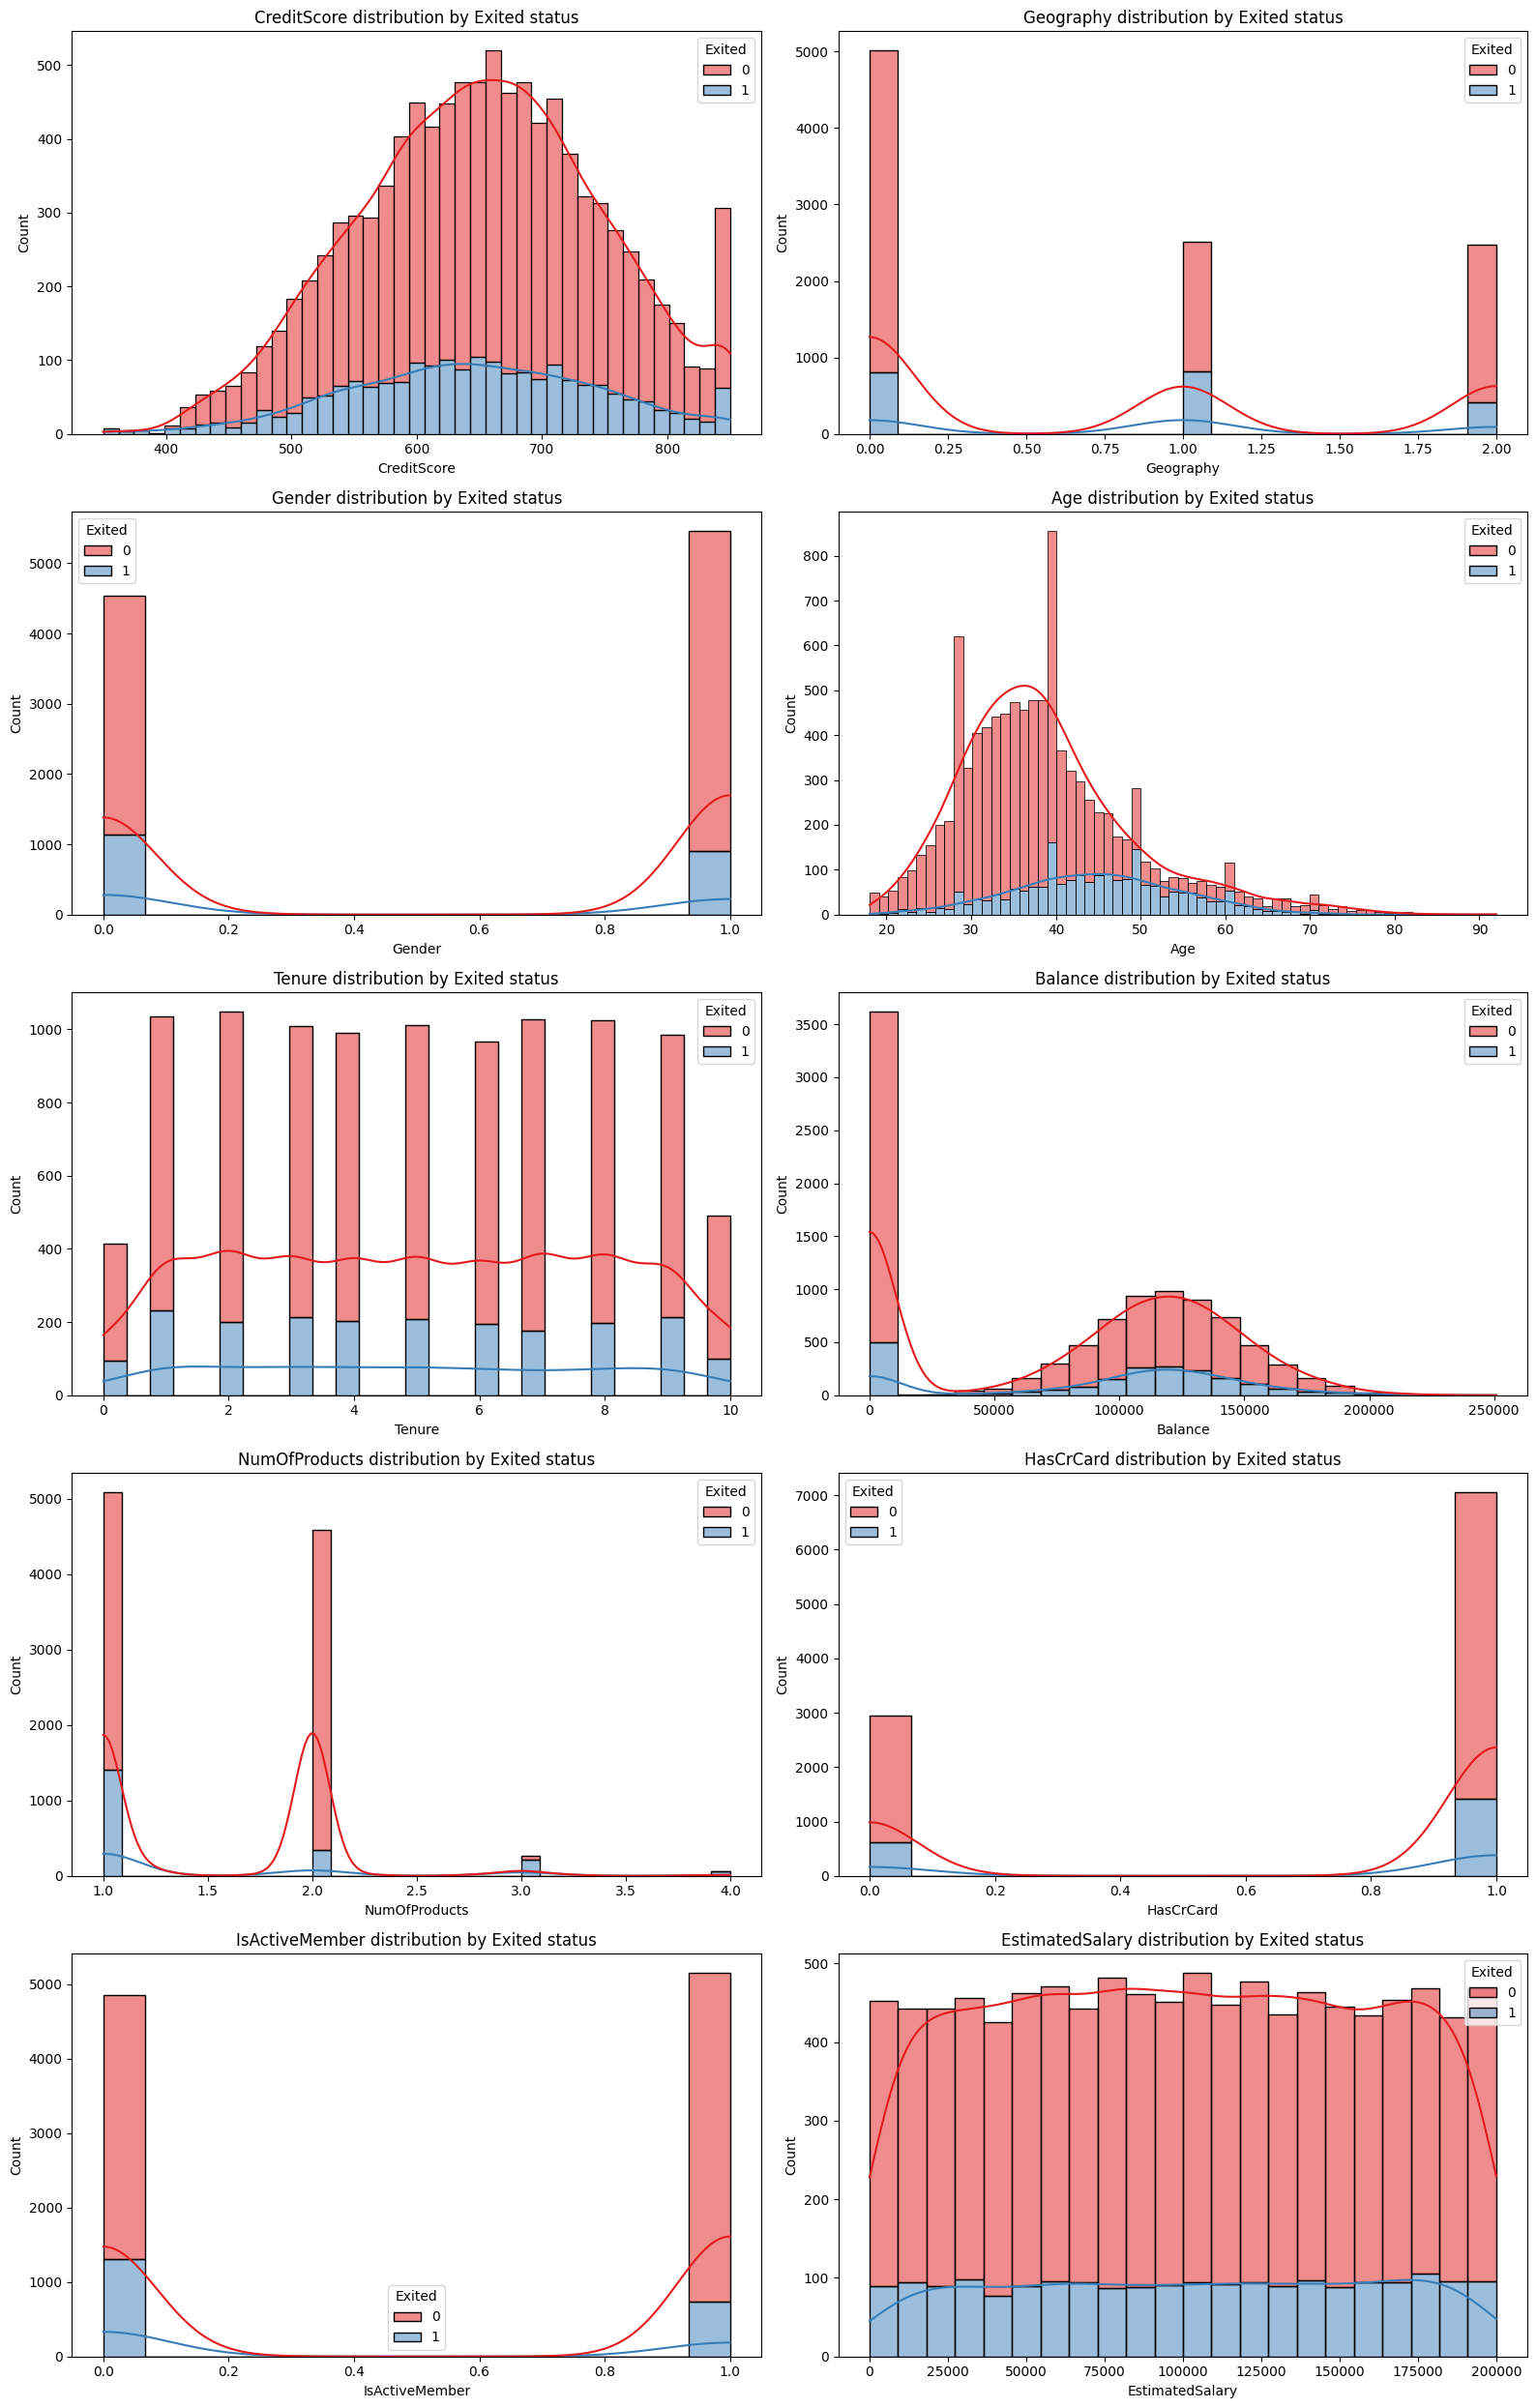

In [20]:
import math

# Identify columns to plot (all except 'Exited')
columns_to_plot = [col for col in df.columns if col != 'Exited']

# Set up the matplotlib grid layout
num_cols = len(columns_to_plot)
plots_per_row = 2
num_rows = math.ceil(num_cols / plots_per_row)

fig, axes = plt.subplots(num_rows, plots_per_row, figsize=(16, num_rows * 5))
axes = axes.flatten()

# Generate histplot for each feature against 'Exited'
for i, col in enumerate(columns_to_plot):
    sns.histplot(
        data=df,
        x=col,
        hue='Exited',
        multiple='stack',
        kde=True,
        ax=axes[i],
        palette='Set1'
    )
    axes[i].set_title(f'{col} distribution by Exited status')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Hide unused subplots if any
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

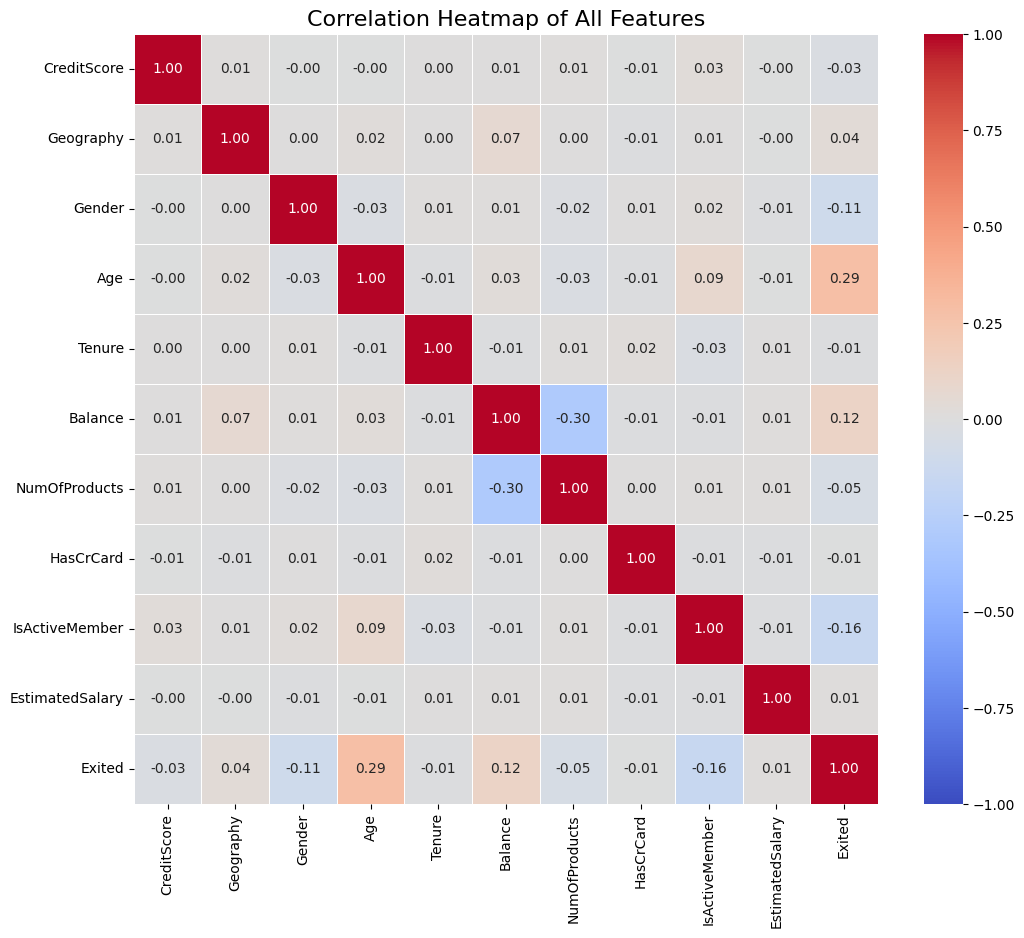

In [21]:
# Calculate the correlation matrix
corr_matrix = df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(12, 10))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of All Features', fontsize=16)
plt.show()

In [23]:
# Extract correlations specifically with the 'Exited' column and sort them
exited_corr = corr_matrix['Exited'].sort_values(ascending=False)

# Convert to a DataFrame for cleaner visualization
exited_corr_df = exited_corr.to_frame(name='Correlation with Exited')

# Display the styled correlations
display(exited_corr_df.style.background_gradient(cmap='coolwarm').format(precision=4))

,Correlation with Exited
Exited,1.0000
Age,0.2853
Balance,0.1185
Geography,0.0359
EstimatedSalary,0.0121
HasCrCard,-0.0071
Tenure,-0.0140
CreditScore,-0.0271
NumOfProducts,-0.0478
Gender,-0.1065


In [25]:
x = df.drop(["Exited","HasCrCard"],axis=1)
y = df["Exited"]

In [26]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [54]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=13)
knn_model.fit(x_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=13)

In [55]:
y_pred = knn_model.predict(x_test_scaled)

In [56]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy_score(y_test,y_pred)

0.8515

In [57]:
confusion_matrix(y_test,y_pred)

array([[1553,   54],
       [ 243,  150]])

In [58]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1607
           1       0.74      0.38      0.50       393

    accuracy                           0.85      2000
   macro avg       0.80      0.67      0.71      2000
weighted avg       0.84      0.85      0.83      2000



In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize Random Forest with class_weight='balanced' to handle the imbalance
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Fit the model on the scaled training data and targets
rf_model.fit(x_train_scaled, y_train)
y_pred_rf = rf_model.predict(x_test_scaled)

# Print metrics
print("--- Random Forest Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

--- Random Forest Results ---
Accuracy Score: 0.8645

Confusion Matrix:
[[1553   54]
 [ 217  176]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1607
           1       0.77      0.45      0.57       393

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.74      2000
weighted avg       0.86      0.86      0.85      2000



In [61]:
import pickle

# Save the trained Random Forest model
model_filename = 'churn_rf_model.pkl'
with open(model_filename, 'wb') as model_file:
    pickle.dump(rf_model, model_file)

# Save the fitted scaler (crucial for scaling new user input during deployment)
scaler_filename = 'scaler.pkl'
with open(scaler_filename, 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

print(f"Successfully saved:\n- {model_filename}\n- {scaler_filename}")

Successfully saved:
- churn_rf_model.pkl
- scaler.pkl


### Next Steps for Deployment
To download these files from Google Colab, you can find them in the file explorer pane on the left, or use the following snippet to trigger a direct download in your browser:
```python
from google.colab import files
files.download('churn_rf_model.pkl')
files.download('scaler.pkl')
```